# Count samples in OG dataset

In [5]:
import csv
from collections import Counter
from pathlib import Path

CSV_FILE = Path("../dataset/PQD-16c-Data/PQD-16C-Data.csv")

counts = Counter()

with open(CSV_FILE, "r", newline="", encoding="utf-8") as file:
    reader = csv.reader(file)

    # Skip header
    next(reader)

    # Read only the first column
    for row in reader:
        if row:
            label = row[0].strip()
            counts[label] += 1


print("PQD-16C DATASET CLASS DISTRIBUTION")
print("=" * 45)
print()

for label, count in sorted(counts.items()):
    print(f"{label}: {count}")

print()
print("=" * 45)
print(f"Total samples: {sum(counts.values())}")
print(f"Total classes: {len(counts)}")

PQD-16C DATASET CLASS DISTRIBUTION

Flicker: 100
Flicker+Harmonics: 100
Flicker+Sag: 100
Flicker+Swell: 100
Harmonics: 100
Impulsive Transient: 100
Interruption: 100
Interruption+Harmonics: 100
Normal: 100
Notch: 100
Oscillatory transient: 100
Sag: 100
Sag+Harmonics: 100
Spike: 100
Swell: 100
Swell+Harmonics: 100

Total samples: 1600
Total classes: 16


# Check graph of each category of class

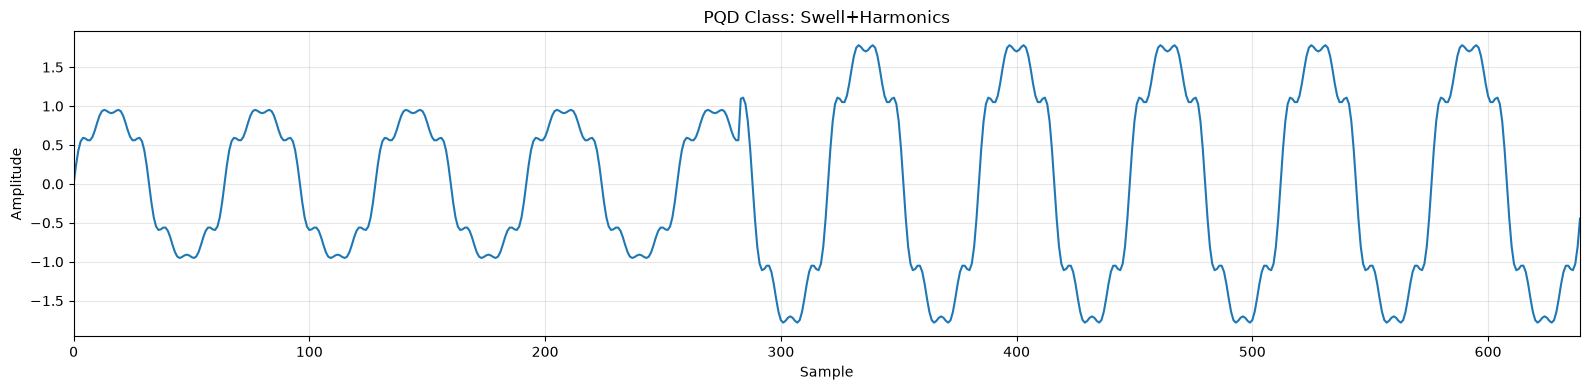

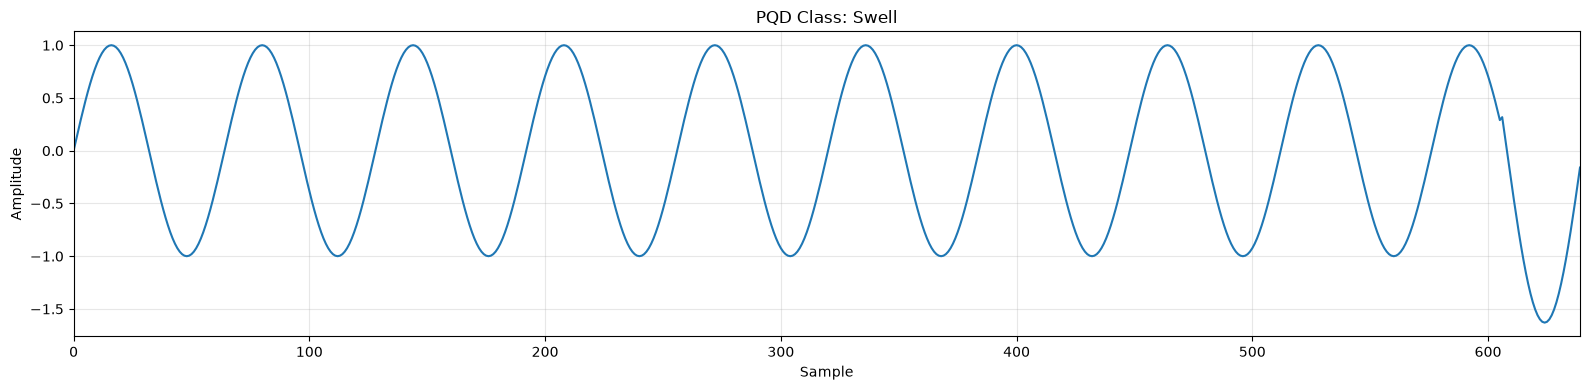

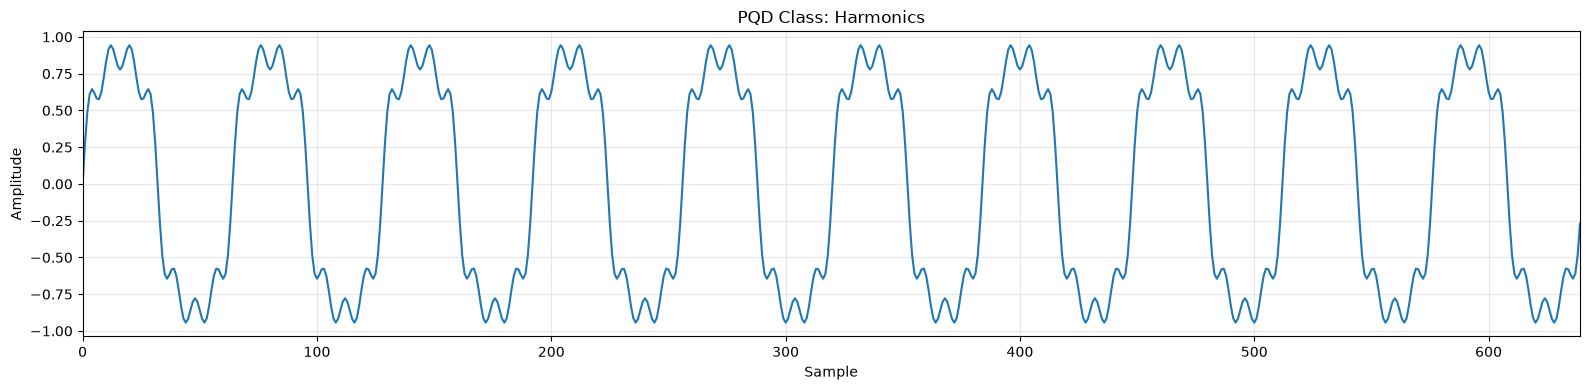

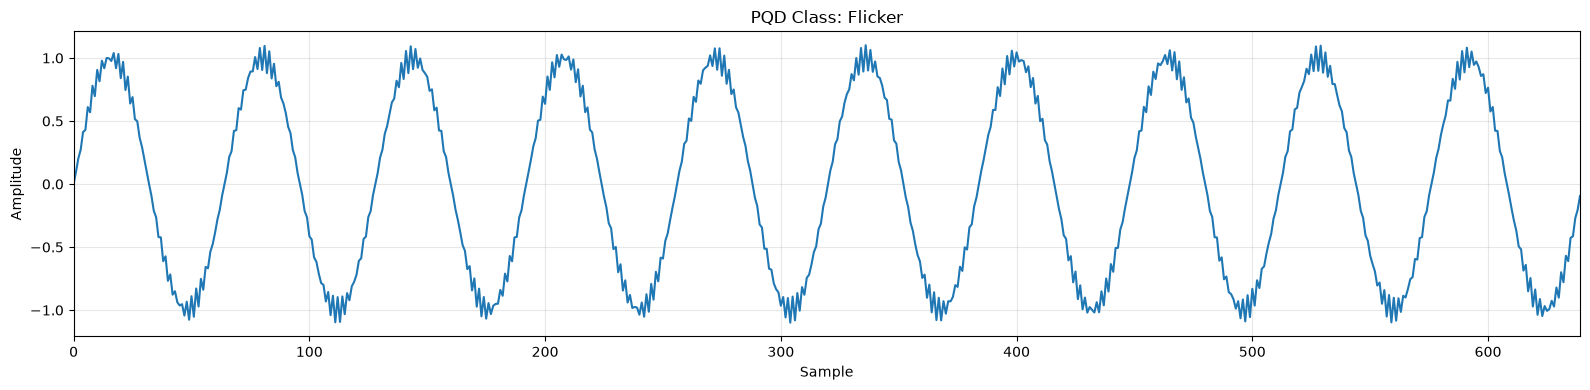

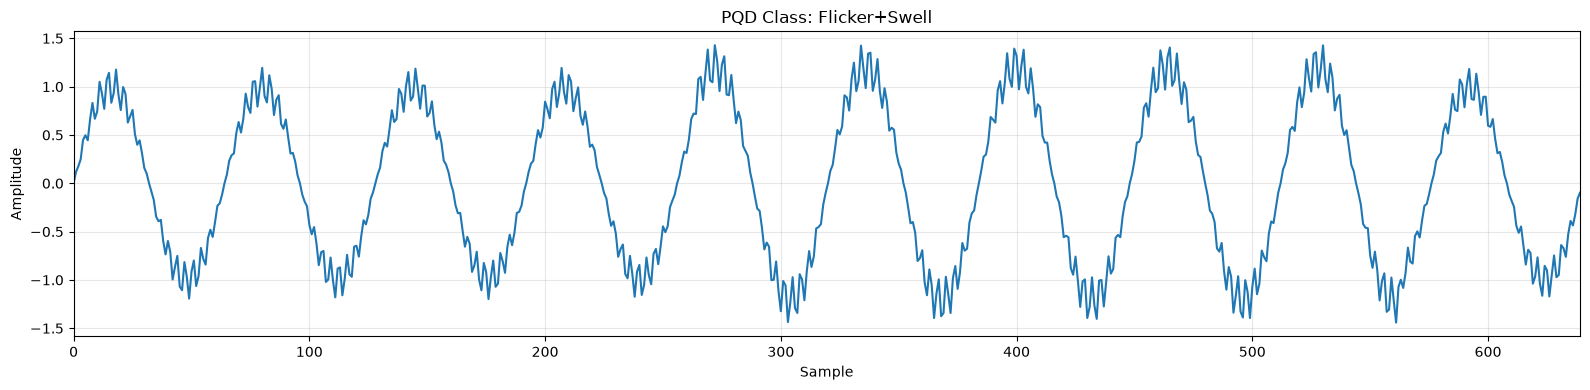

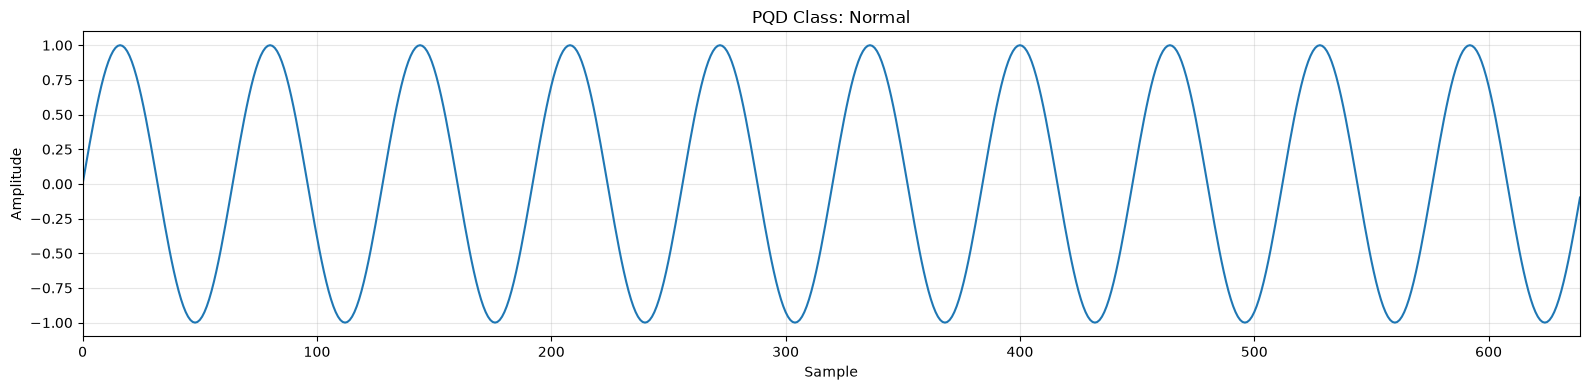

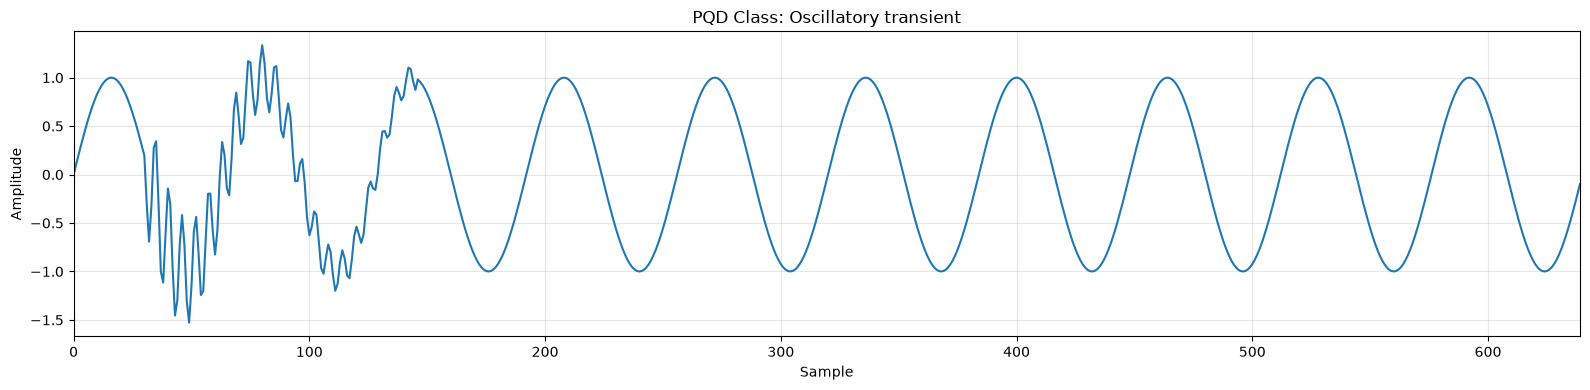

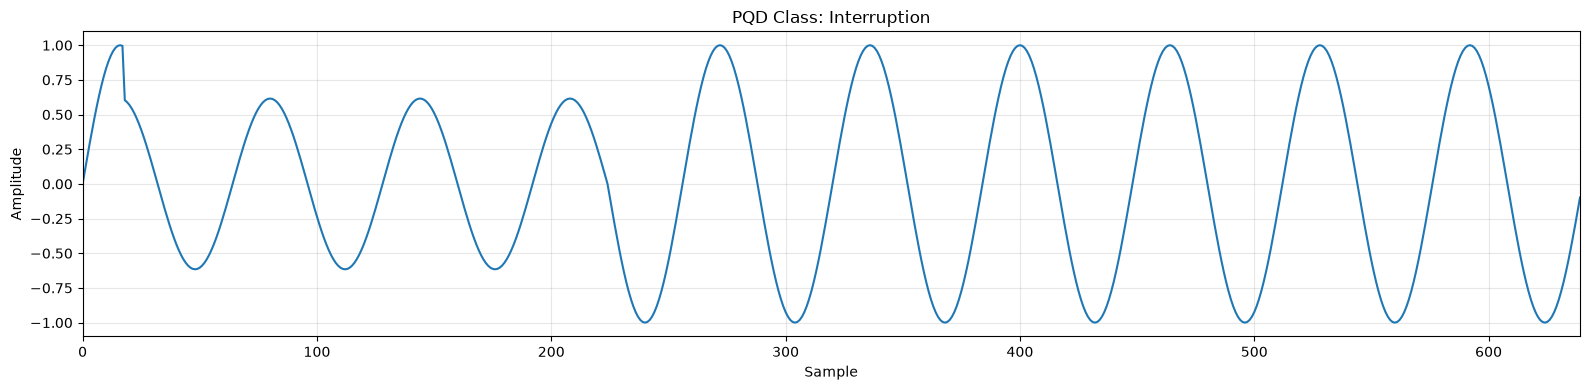

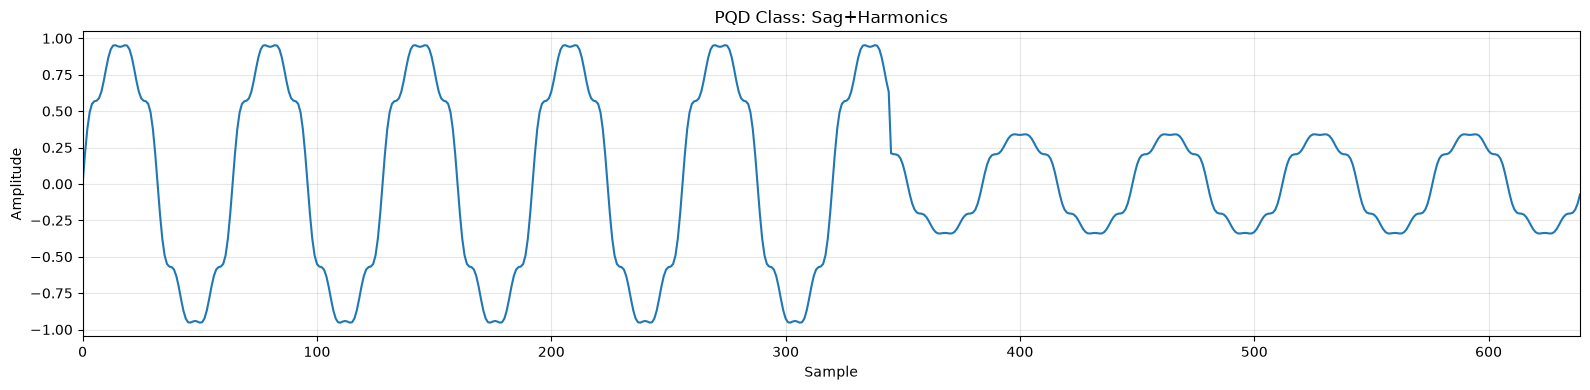

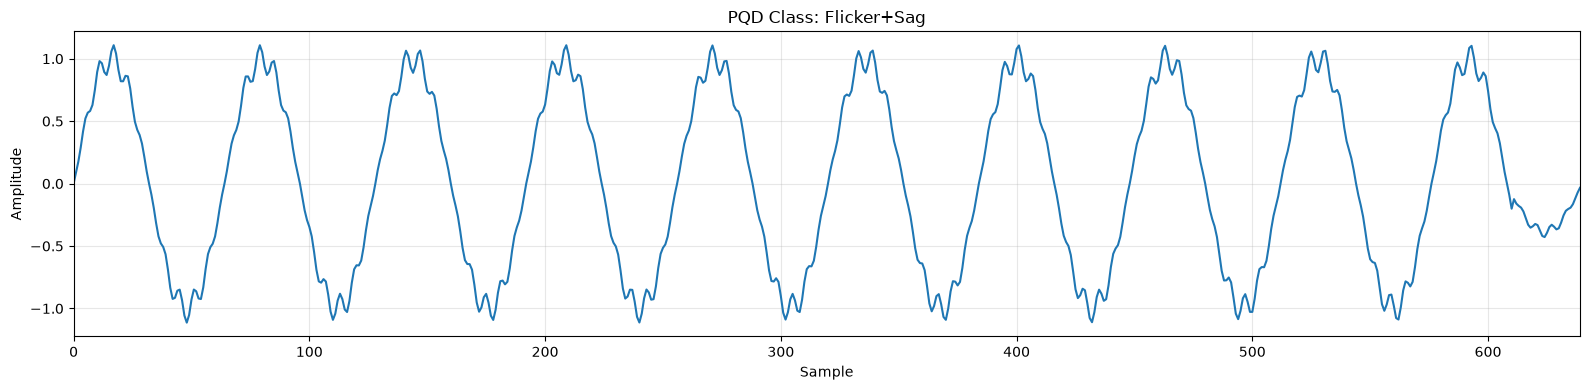

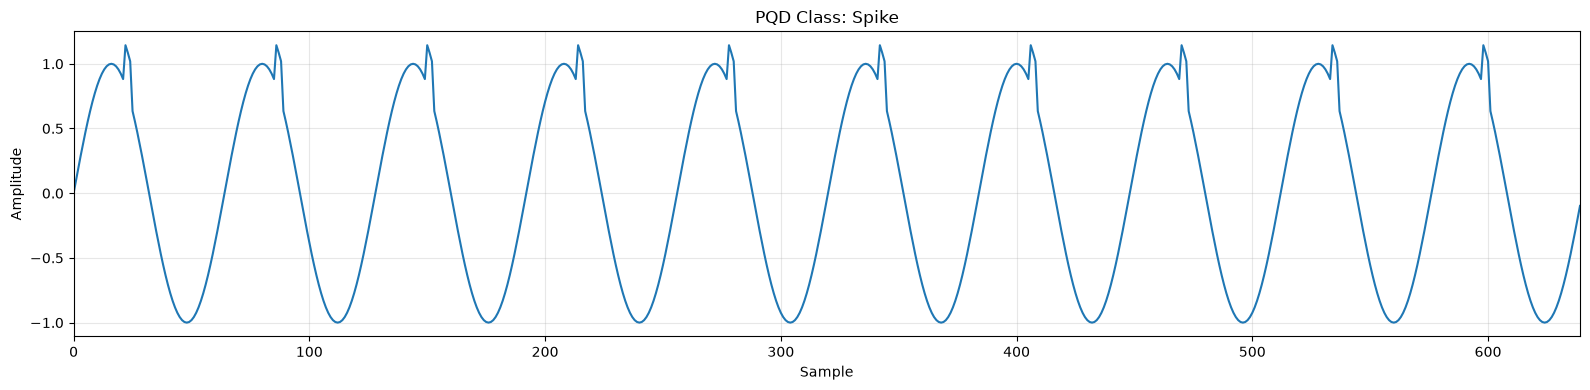

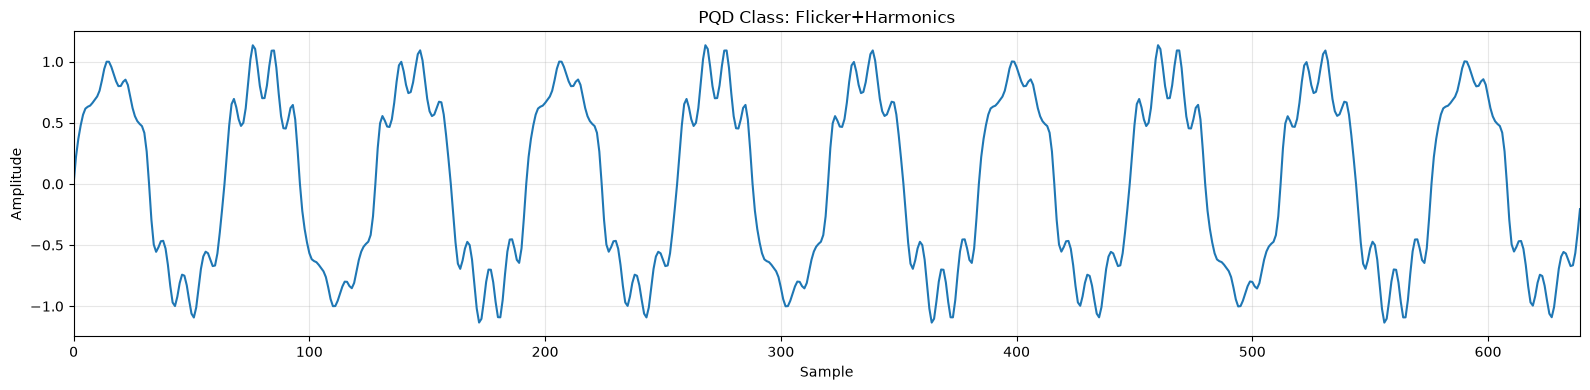

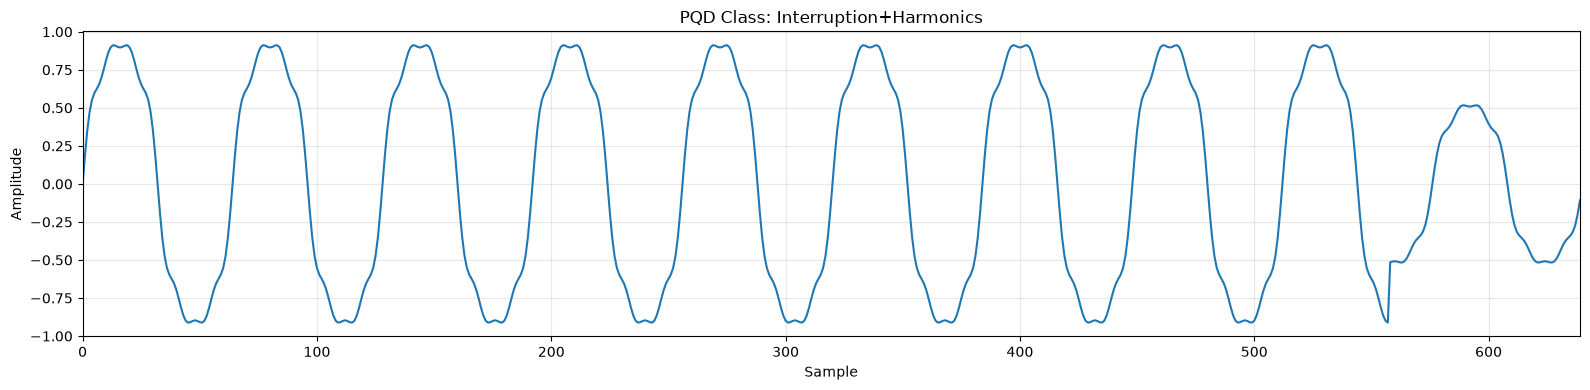

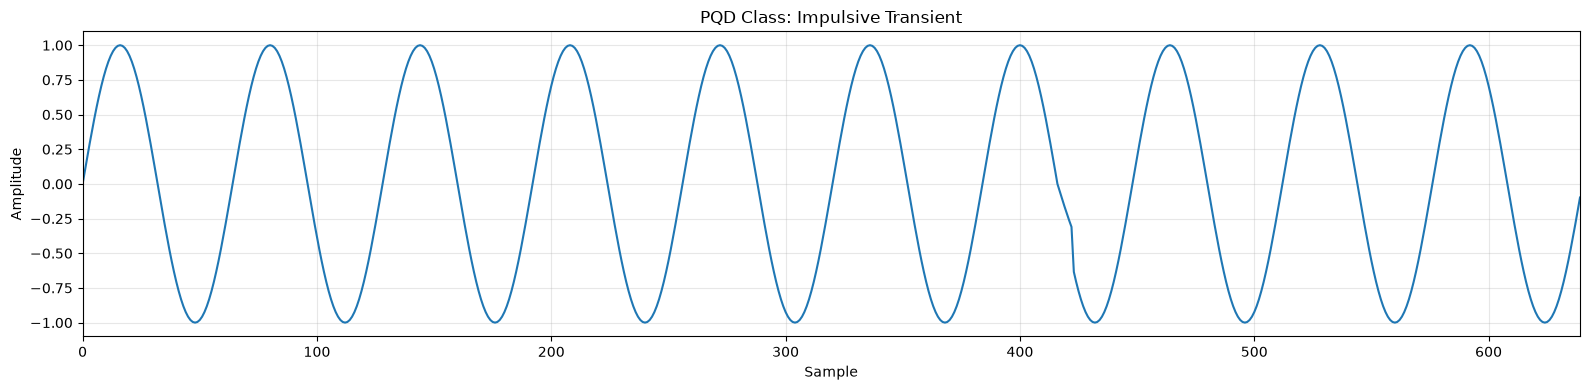

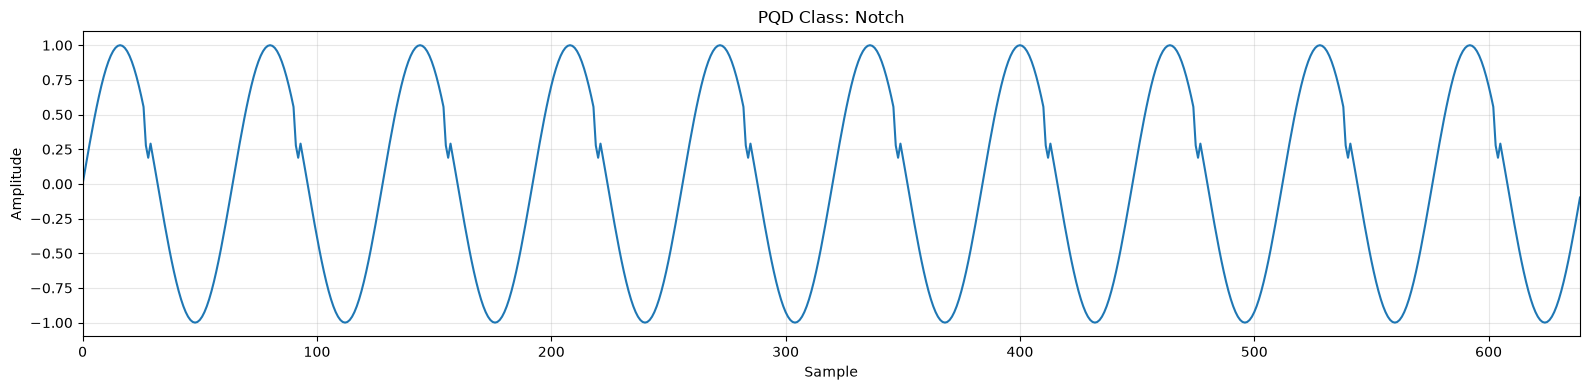

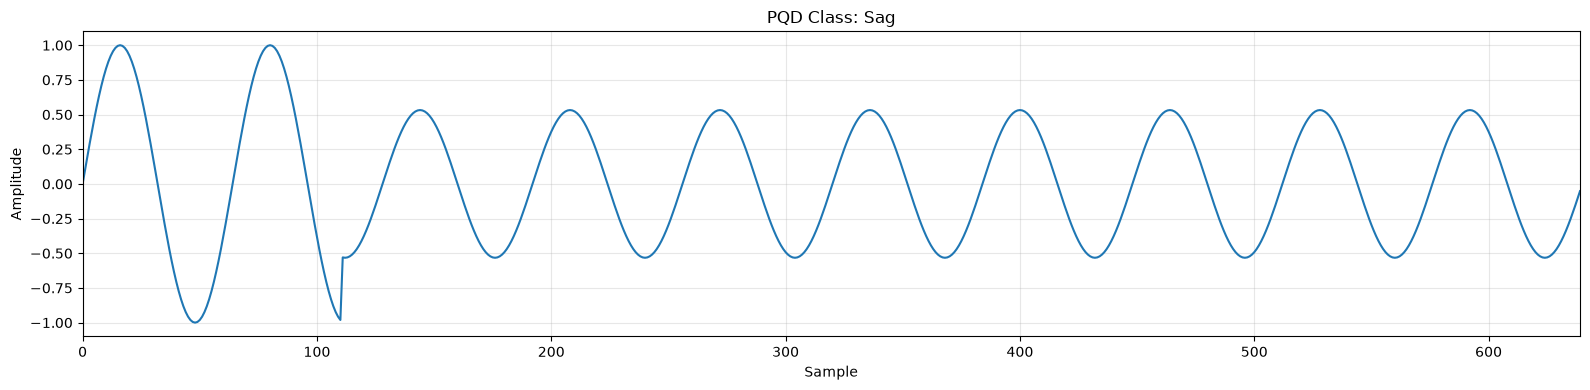

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# --------------------------------------------------
# Configuration
# --------------------------------------------------

CSV_FILE = Path("../dataset/PQD-16c-Data/PQD-16C-Data.csv")

# --------------------------------------------------
# Load dataset
# --------------------------------------------------

df = pd.read_csv(CSV_FILE)

label_column = df.columns[0]
signal_columns = df.columns[1:]

# --------------------------------------------------
# Plot one random waveform from each class
# --------------------------------------------------

for label in df[label_column].unique():

    # Get all samples belonging to this class
    class_samples = df[df[label_column] == label]

    # Select one random waveform
    row = class_samples.sample(n=1).iloc[0]

    # Extract the 640 signal samples
    signal = row[signal_columns].astype(float).values

    # --------------------------------------------------
    # Plot
    # --------------------------------------------------

    plt.figure(figsize=(16, 4))

    plt.plot(signal)

    plt.title(f"PQD Class: {label}")
    plt.xlabel("Sample")
    plt.ylabel("Amplitude")
    plt.xlim(0, 639)

    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    plt.show()

# Split dataset into Train and Test

In [7]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split


# ============================================================
# CONFIGURATION
# ============================================================

CSV_FILE = Path("../dataset/PQD-16c-Data/PQD-16C-Data.csv")

RANDOM_STATE = 42

TRAIN_SIZE = 1024
VAL_SIZE = 256
TEST_SIZE = 320


# ============================================================
# LOAD ORIGINAL DATASET
# ============================================================

df = pd.read_csv(CSV_FILE)

print("=" * 60)
print("LOADING ORIGINAL DATASET")
print("=" * 60)

print("Original dataset:", df.shape)
print("First columns:", df.columns[:5].tolist())


# ============================================================
# FIRST COLUMN = LABEL
# REMAINING 640 COLUMNS = SIGNAL
# ============================================================

label_column = df.columns[0]
signal_columns = df.columns[1:]

y = df.iloc[:, 0].values
X = df.iloc[:, 1:].values


print()
print("X:", X.shape)
print("y:", y.shape)


# ============================================================
# VERIFY DATASET
# ============================================================

assert len(X) == len(y)

assert X.shape[1] == 640

assert (
    TRAIN_SIZE + VAL_SIZE + TEST_SIZE
    == len(X)
)


# ============================================================
# FIRST SPLIT
#
# 1024 TRAIN
# 576 TEMPORARY
# ============================================================

X_train, X_temp, y_train, y_temp = train_test_split(

    X,
    y,

    train_size=TRAIN_SIZE,

    random_state=RANDOM_STATE,

    shuffle=True,

    stratify=y
)


# ============================================================
# SECOND SPLIT
#
# 256 VALIDATION
# 320 TEST
# ============================================================

X_val, X_test, y_val, y_test = train_test_split(

    X_temp,
    y_temp,

    train_size=VAL_SIZE,
    test_size=TEST_SIZE,

    random_state=RANDOM_STATE,

    shuffle=True,

    stratify=y_temp
)


# ============================================================
# CHECK FINAL SPLIT
# ============================================================

print()
print("=" * 60)
print("FINAL RANDOM SPLIT")
print("=" * 60)

print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

print()

print("y_train:", y_train.shape)
print("y_val  :", y_val.shape)
print("y_test :", y_test.shape)


# ============================================================
# CLASS DISTRIBUTION
# ============================================================

print()
print("=" * 60)
print("CLASS DISTRIBUTION")
print("=" * 60)

print("\nTrain:")
print(
    pd.Series(y_train)
    .value_counts()
    .sort_index()
)

print("\nValidation:")
print(
    pd.Series(y_val)
    .value_counts()
    .sort_index()
)

print("\nTest:")
print(
    pd.Series(y_test)
    .value_counts()
    .sort_index()
)


# ============================================================
# CREATE DATAFRAMES
#
# PRESERVE ORIGINAL FORMAT:
#
# FIRST COLUMN = LABEL
# NEXT 640 COLUMNS = SIGNAL
# ============================================================

def create_dataframe(X_data, y_data):

    result = pd.DataFrame(
        X_data,
        columns=signal_columns
    )

    result.insert(
        0,
        label_column,
        y_data
    )

    return result


train_df = create_dataframe(
    X_train,
    y_train
)

val_df = create_dataframe(
    X_val,
    y_val
)

test_df = create_dataframe(
    X_test,
    y_test
)


# ============================================================
# SAVE
# ============================================================

TRAIN_CSV = CSV_FILE.parent / "train.csv"
VAL_CSV = CSV_FILE.parent / "validation.csv"
TEST_CSV = CSV_FILE.parent / "test.csv"


train_df.to_csv(
    TRAIN_CSV,
    index=False
)

val_df.to_csv(
    VAL_CSV,
    index=False
)

test_df.to_csv(
    TEST_CSV,
    index=False
)


# ============================================================
# VERIFY SAVED DATA
# ============================================================

print()
print("=" * 60)
print("SAVED")
print("=" * 60)

print("Train:", TRAIN_CSV.resolve())
print("Validation:", VAL_CSV.resolve())
print("Test:", TEST_CSV.resolve())

print()

print("Train CSV:", train_df.shape)
print("Validation CSV:", val_df.shape)
print("Test CSV:", test_df.shape)

print()

print("First 5 columns:")
print(train_df.columns[:5].tolist())

LOADING ORIGINAL DATASET
Original dataset: (1600, 641)
First columns: ['labels', 'signals_1', 'signals_2', 'signals_3', 'signals_4']

X: (1600, 640)
y: (1600,)

FINAL RANDOM SPLIT
X_train: (1024, 640)
X_val  : (256, 640)
X_test : (320, 640)

y_train: (1024,)
y_val  : (256,)
y_test : (320,)

CLASS DISTRIBUTION

Train:
Flicker                   64
Flicker+Harmonics         64
Flicker+Sag               64
Flicker+Swell             64
Harmonics                 64
Impulsive Transient       64
Interruption              64
Interruption+Harmonics    64
Normal                    64
Notch                     64
Oscillatory transient     64
Sag                       64
Sag+Harmonics             64
Spike                     64
Swell                     64
Swell+Harmonics           64
Name: count, dtype: int64

Validation:
Flicker                   16
Flicker+Harmonics         16
Flicker+Sag               16
Flicker+Swell             16
Harmonics                 16
Impulsive Transient       16
Inte

# Regularized Residual 1D CNN - RUN THE MODEL

### No need to run everytime, we already have the trained .pth file

In [10]:
# ============================================================
# 1D CNN POWER QUALITY CLASSIFICATION
# Optimized Residual CNN
#
# Dataset:
#   train.csv
#   validation.csv
#   test.csv
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torch.utils.data import TensorDataset, DataLoader


# ============================================================
# 2. CONFIGURATION
# ============================================================

SEED = 42

DATA_DIR = Path(
    "../dataset/PQD-16c-Data"
)

TRAIN_CSV = DATA_DIR / "train.csv"
VAL_CSV   = DATA_DIR / "validation.csv"
TEST_CSV  = DATA_DIR / "test.csv"

BATCH_SIZE = 64

EPOCHS = 100

PATIENCE = 15


# ============================================================
# 3. REPRODUCIBILITY
# ============================================================

random.seed(SEED)

np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():

    torch.cuda.manual_seed_all(SEED)


# ============================================================
# 4. DEVICE
# ============================================================

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


print("=" * 60)
print("1D CNN POWER QUALITY CLASSIFICATION")
print("=" * 60)

print("Device:", device)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

print()


# ============================================================
# 5. LOAD SPLIT CSV FILES
# ============================================================

print("=" * 60)
print("LOADING DATASET")
print("=" * 60)


train_df = pd.read_csv(
    TRAIN_CSV
)

val_df = pd.read_csv(
    VAL_CSV
)

test_df = pd.read_csv(
    TEST_CSV
)


print(
    "Train CSV:",
    train_df.shape
)

print(
    "Validation CSV:",
    val_df.shape
)

print(
    "Test CSV:",
    test_df.shape
)


# ============================================================
# 6. EXTRACT LABELS AND SIGNALS
# ============================================================
#
# CSV format:
#
#   column 0  -> labels
#   columns 1:641 -> 640 signal samples
#
# ============================================================


LABEL_COLUMN = train_df.columns[0]

SIGNAL_COLUMNS = train_df.columns[1:]


# ------------------------------------------------------------
# Verify all CSVs have the same structure
# ------------------------------------------------------------

assert val_df.columns.tolist() == train_df.columns.tolist()

assert test_df.columns.tolist() == train_df.columns.tolist()

assert len(SIGNAL_COLUMNS) == 640


# ------------------------------------------------------------
# Extract data
# ------------------------------------------------------------

y_train_raw = train_df[LABEL_COLUMN].values

y_val_raw = val_df[LABEL_COLUMN].values

y_test_raw = test_df[LABEL_COLUMN].values


X_train = train_df[SIGNAL_COLUMNS].values.astype(
    np.float32
)

X_val = val_df[SIGNAL_COLUMNS].values.astype(
    np.float32
)

X_test = test_df[SIGNAL_COLUMNS].values.astype(
    np.float32
)


print()
print("Signals:")
print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

print()
print("Labels:")
print("y_train:", y_train_raw.shape)
print("y_val  :", y_val_raw.shape)
print("y_test :", y_test_raw.shape)


# ============================================================
# 7. LABEL ENCODING
# ============================================================
#
# IMPORTANT:
# Encode labels using the complete set of class names.
#
# Since all splits contain all 16 classes, this will produce
# the same mapping for every split.
#
# ============================================================


class_names = sorted(
    np.unique(y_train_raw)
)


NUM_CLASSES = len(
    class_names
)


label_to_index = {
    label: index
    for index, label in enumerate(class_names)
}


print()
print("=" * 60)
print("CLASSES")
print("=" * 60)


for index, label in enumerate(class_names):

    print(
        f"{index:2d} -> {label}"
    )


print()
print(
    "Number of classes:",
    NUM_CLASSES
)


assert NUM_CLASSES == 16


# ------------------------------------------------------------
# Convert string labels -> integer labels
# ------------------------------------------------------------

y_train = np.array(
    [
        label_to_index[label]
        for label in y_train_raw
    ],
    dtype=np.int64
)


y_val = np.array(
    [
        label_to_index[label]
        for label in y_val_raw
    ],
    dtype=np.int64
)


y_test = np.array(
    [
        label_to_index[label]
        for label in y_test_raw
    ],
    dtype=np.int64
)


# ============================================================
# 8. CLASS DISTRIBUTION CHECK
# ============================================================

print()
print("=" * 60)
print("CLASS DISTRIBUTION")
print("=" * 60)


print("\nTrain:")

print(
    pd.Series(y_train_raw)
    .value_counts()
    .sort_index()
)


print("\nValidation:")

print(
    pd.Series(y_val_raw)
    .value_counts()
    .sort_index()
)


print("\nTest:")

print(
    pd.Series(y_test_raw)
    .value_counts()
    .sort_index()
)


# ============================================================
# 9. SANITY CHECKS
# ============================================================

assert X_train.shape == (1024, 640)

assert X_val.shape == (256, 640)

assert X_test.shape == (320, 640)


assert y_train.shape == (1024,)

assert y_val.shape == (256,)

assert y_test.shape == (320,)


# ============================================================
# 10. NORMALIZATION
# ============================================================
#
# VERY IMPORTANT:
#
# Mean/std are calculated ONLY from training data.
#
# Validation and test data never participate in calculating
# normalization statistics.
#
# This avoids data leakage.
#
# ============================================================


train_mean = X_train.mean()

train_std = X_train.std()


print()
print("=" * 60)
print("NORMALIZATION")
print("=" * 60)

print(
    f"Training mean: {train_mean:.8f}"
)

print(
    f"Training std : {train_std:.8f}"
)


# ------------------------------------------------------------
# Normalize all splits using TRAIN statistics
# ------------------------------------------------------------

X_train = (
    X_train - train_mean
) / train_std


X_val = (
    X_val - train_mean
) / train_std


X_test = (
    X_test - train_mean
) / train_std


# ============================================================
# 11. PREPARE CNN INPUT
# ============================================================
#
# Current:
#
#     [N, 640]
#
# CNN expects:
#
#     [N, channels, sequence_length]
#
# Therefore:
#
#     [N, 1, 640]
#
# ============================================================


X_train_t = torch.tensor(
    X_train,
    dtype=torch.float32
).unsqueeze(1)


X_val_t = torch.tensor(
    X_val,
    dtype=torch.float32
).unsqueeze(1)


X_test_t = torch.tensor(
    X_test,
    dtype=torch.float32
).unsqueeze(1)


y_train_t = torch.tensor(
    y_train,
    dtype=torch.long
)


y_val_t = torch.tensor(
    y_val,
    dtype=torch.long
)


y_test_t = torch.tensor(
    y_test,
    dtype=torch.long
)


# ============================================================
# 12. FINAL INPUT SHAPES
# ============================================================

print()
print("=" * 60)
print("FINAL INPUT SHAPES")
print("=" * 60)

print(
    "X_train:",
    X_train_t.shape
)

print(
    "X_val  :",
    X_val_t.shape
)

print(
    "X_test :",
    X_test_t.shape
)

print(
    "y_train:",
    y_train_t.shape
)

print(
    "y_val  :",
    y_val_t.shape
)

print(
    "y_test :",
    y_test_t.shape
)


# ============================================================
# 13. FINAL SANITY CHECKS
# ============================================================

assert X_train_t.shape == (
    1024,
    1,
    640
)

assert X_val_t.shape == (
    256,
    1,
    640
)

assert X_test_t.shape == (
    320,
    1,
    640
)


assert len(
    X_train_t
) == len(
    y_train_t
)


assert len(
    X_val_t
) == len(
    y_val_t
)


assert len(
    X_test_t
) == len(
    y_test_t
)


# ============================================================
# 14. DATASETS
# ============================================================

train_dataset = TensorDataset(
    X_train_t,
    y_train_t
)


val_dataset = TensorDataset(
    X_val_t,
    y_val_t
)


test_dataset = TensorDataset(
    X_test_t,
    y_test_t
)


# ============================================================
# 15. DATA LOADERS
# ============================================================

train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=0
)


val_loader = DataLoader(

    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=0
)


test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=0
)


# ============================================================
# 16. SIGNAL AUGMENTATION
# ============================================================

def augment_signal(x):

    """
    Mild augmentation for 1D power-quality signals.

    Input:
        [B, 1, 640]
    """

    x = x.clone()


    # --------------------------------------------------------
    # Gaussian noise
    # --------------------------------------------------------

    if random.random() < 0.5:

        noise_std = 0.008

        noise = (
            torch.randn_like(x)
            * noise_std
        )

        x = x + noise


    # --------------------------------------------------------
    # Amplitude scaling
    # --------------------------------------------------------

    if random.random() < 0.4:

        scale = torch.empty(

            x.size(0),
            1,
            1,

            device=x.device

        ).uniform_(
            0.97,
            1.03
        )

        x = x * scale


    # --------------------------------------------------------
    # DC shift
    # --------------------------------------------------------

    if random.random() < 0.2:

        shift = torch.empty(

            x.size(0),
            1,
            1,

            device=x.device

        ).uniform_(
            -0.01,
            0.01
        )

        x = x + shift


    return x


# ============================================================
# 17. RESIDUAL BLOCK
# ============================================================

class ResidualBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        stride=1,
        dropout=0.05
    ):

        super().__init__()


        self.conv1 = nn.Conv1d(

            in_channels,

            out_channels,

            kernel_size=5,

            stride=stride,

            padding=2,

            bias=False
        )


        self.bn1 = nn.BatchNorm1d(
            out_channels
        )


        self.conv2 = nn.Conv1d(

            out_channels,

            out_channels,

            kernel_size=5,

            stride=1,

            padding=2,

            bias=False
        )


        self.bn2 = nn.BatchNorm1d(
            out_channels
        )


        self.relu = nn.ReLU(
            inplace=True
        )


        self.dropout = nn.Dropout(
            dropout
        )


        if (
            stride != 1
            or
            in_channels != out_channels
        ):

            self.shortcut = nn.Sequential(

                nn.Conv1d(

                    in_channels,

                    out_channels,

                    kernel_size=1,

                    stride=stride,

                    bias=False
                ),

                nn.BatchNorm1d(
                    out_channels
                )
            )

        else:

            self.shortcut = nn.Identity()


    def forward(self, x):

        identity = self.shortcut(x)


        out = self.conv1(x)

        out = self.bn1(out)

        out = self.relu(out)

        out = self.dropout(out)


        out = self.conv2(out)

        out = self.bn2(out)


        out = out + identity

        out = self.relu(out)


        return out


# ============================================================
# 18. CNN MODEL
# ============================================================

class CNNPQ(nn.Module):

    def __init__(
        self,
        num_classes=16
    ):

        super().__init__()


        # ----------------------------------------------------
        # STEM
        # ----------------------------------------------------

        self.stem = nn.Sequential(

            nn.Conv1d(

                1,

                32,

                kernel_size=7,

                padding=3,

                bias=False
            ),

            nn.BatchNorm1d(
                32
            ),

            nn.ReLU(
                inplace=True
            )
        )


        # ----------------------------------------------------
        # RESIDUAL FEATURE EXTRACTOR
        #
        # 640
        #  ↓ stride 2
        # 320
        #  ↓ stride 2
        # 160
        #  ↓ stride 2
        # 80
        #  ↓
        # 80
        #
        # ----------------------------------------------------

        self.features = nn.Sequential(

            ResidualBlock(

                32,

                32,

                stride=2,

                dropout=0.05
            ),


            ResidualBlock(

                32,

                64,

                stride=2,

                dropout=0.05
            ),


            ResidualBlock(

                64,

                96,

                stride=2,

                dropout=0.10
            ),


            ResidualBlock(

                96,

                96,

                stride=1,

                dropout=0.10
            )
        )


        # ----------------------------------------------------
        # GLOBAL AVERAGE POOLING
        # ----------------------------------------------------

        self.pool = nn.AdaptiveAvgPool1d(
            1
        )


        # ----------------------------------------------------
        # CLASSIFIER
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                96,
                48
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Dropout(
                0.30
            ),

            nn.Linear(
                48,
                num_classes
            )
        )


    def forward(self, x):

        x = self.stem(x)

        x = self.features(x)

        x = self.pool(x)

        x = self.classifier(x)

        return x


# ============================================================
# 19. CREATE MODEL
# ============================================================

model = CNNPQ(
    num_classes=NUM_CLASSES
).to(device)


# ============================================================
# 20. PARAMETER COUNT
# ============================================================

num_params = sum(

    p.numel()

    for p in model.parameters()

    if p.requires_grad
)


print()
print("=" * 60)
print("MODEL")
print("=" * 60)

print(model)

print()

print(
    f"Trainable parameters: {num_params:,}"
)


# ============================================================
# 21. LOSS
# ============================================================

criterion = nn.CrossEntropyLoss(

    label_smoothing=0.05
)


# ============================================================
# 22. OPTIMIZER
# ============================================================

optimizer = torch.optim.AdamW(

    model.parameters(),

    lr=1e-3,

    weight_decay=1e-4
)


# ============================================================
# 23. LEARNING RATE SCHEDULER
# ============================================================

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(

    optimizer,

    mode="min",

    factor=0.5,

    patience=7,

    min_lr=1e-6
)


# ============================================================
# 24. TRAINING SETTINGS
# ============================================================

best_val_loss = float(
    "inf"
)

best_val_acc = 0.0

best_state = None

epochs_without_improvement = 0


# ============================================================
# 25. TRAINING
# ============================================================

print()
print("=" * 60)
print("TRAINING")
print("=" * 60)


for epoch in range(
    EPOCHS
):


    # ========================================================
    # TRAIN
    # ========================================================

    model.train()


    train_loss = 0.0

    train_correct = 0

    train_total = 0


    for xb, yb in train_loader:


        xb = xb.to(device)

        yb = yb.to(device)


        # ----------------------------------------------------
        # AUGMENT TRAINING DATA
        # ----------------------------------------------------

        xb_aug = augment_signal(
            xb
        )


        # ----------------------------------------------------
        # FORWARD
        # ----------------------------------------------------

        optimizer.zero_grad(
            set_to_none=True
        )


        logits = model(
            xb_aug
        )


        loss = criterion(
            logits,
            yb
        )


        # ----------------------------------------------------
        # BACKPROPAGATION
        # ----------------------------------------------------

        loss.backward()


        # ----------------------------------------------------
        # GRADIENT CLIPPING
        # ----------------------------------------------------

        torch.nn.utils.clip_grad_norm_(

            model.parameters(),

            max_norm=1.0
        )


        # ----------------------------------------------------
        # UPDATE
        # ----------------------------------------------------

        optimizer.step()


        # ----------------------------------------------------
        # METRICS
        # ----------------------------------------------------

        train_loss += (
            loss.item()
            * xb.size(0)
        )


        predictions = logits.argmax(
            dim=1
        )


        train_correct += (

            predictions == yb

        ).sum().item()


        train_total += xb.size(0)


    train_loss /= train_total


    train_acc = (
        100.0
        * train_correct
        / train_total
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()


    val_loss = 0.0

    val_correct = 0

    val_total = 0


    with torch.no_grad():

        for xb, yb in val_loader:


            xb = xb.to(device)

            yb = yb.to(device)


            logits = model(
                xb
            )


            loss = criterion(
                logits,
                yb
            )


            val_loss += (

                loss.item()
                * xb.size(0)

            )


            predictions = logits.argmax(
                dim=1
            )


            val_correct += (

                predictions == yb

            ).sum().item()


            val_total += xb.size(0)


    val_loss /= val_total


    val_acc = (

        100.0
        * val_correct
        / val_total

    )


    # ========================================================
    # LEARNING RATE
    # ========================================================

    scheduler.step(
        val_loss
    )


    current_lr = (
        optimizer
        .param_groups[0]["lr"]
    )


    # ========================================================
    # PRINT
    # ========================================================

    print(

        f"Epoch [{epoch + 1:03d}/{EPOCHS}] | "

        f"Train Loss: {train_loss:.4f} | "

        f"Train Acc: {train_acc:6.2f}% | "

        f"Val Loss: {val_loss:.4f} | "

        f"Val Acc: {val_acc:6.2f}% | "

        f"LR: {current_lr:.2e}"

    )


    # ========================================================
    # BEST MODEL
    # ========================================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_val_acc = val_acc

        best_state = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if (
        epochs_without_improvement
        >= PATIENCE
    ):

        print()

        print(
            f"Early stopping at epoch "
            f"{epoch + 1}"
        )

        break


# ============================================================
# 26. RESTORE BEST MODEL
# ============================================================

if best_state is not None:

    model.load_state_dict(
        best_state
    )


# ============================================================
# 27. BEST VALIDATION RESULT
# ============================================================

print()
print("=" * 60)
print("BEST VALIDATION RESULT")
print("=" * 60)


print(
    f"Best Val Loss : "
    f"{best_val_loss:.4f}"
)


print(
    f"Best Val Acc  : "
    f"{best_val_acc:.2f}%"
)


# ============================================================
# 28. TEST
# ============================================================

model.eval()


test_loss = 0.0

test_correct = 0

test_total = 0


with torch.no_grad():

    for xb, yb in test_loader:


        xb = xb.to(device)

        yb = yb.to(device)


        logits = model(
            xb
        )


        loss = criterion(
            logits,
            yb
        )


        test_loss += (

            loss.item()
            * xb.size(0)

        )


        predictions = logits.argmax(
            dim=1
        )


        test_correct += (

            predictions == yb

        ).sum().item()


        test_total += xb.size(0)


test_loss /= test_total


test_acc = (

    100.0
    * test_correct
    / test_total

)


# ============================================================
# 29. FINAL TEST RESULT
# ============================================================

print()
print("=" * 60)
print("FINAL TEST RESULT")
print("=" * 60)


print(
    f"Test Loss : "
    f"{test_loss:.4f}"
)


print(
    f"Test Acc  : "
    f"{test_acc:.2f}%"
)


# ============================================================
# 30. SAVE BEST MODEL
# ============================================================

MODEL_DIR = Path("../models")

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_PATH = (
    MODEL_DIR
    / "cnn_pq_best.pth"
)


torch.save(

    {

        "model_state_dict":
            model.state_dict(),

        "num_classes":
            NUM_CLASSES,

        "class_names":
            class_names,

        "input_shape":
            [1, 640],

        "train_mean":
            float(train_mean),

        "train_std":
            float(train_std),

        "test_accuracy":
            test_acc,

        "best_val_accuracy":
            best_val_acc,

        "best_val_loss":
            best_val_loss

    },

    MODEL_PATH
)


print()
print("=" * 60)
print("SAVED")
print("=" * 60)

print(
    MODEL_PATH.resolve()
)

1D CNN POWER QUALITY CLASSIFICATION
Device: cpu

LOADING DATASET
Train CSV: (1024, 641)
Validation CSV: (256, 641)
Test CSV: (320, 641)

Signals:
X_train: (1024, 640)
X_val  : (256, 640)
X_test : (320, 640)

Labels:
y_train: (1024,)
y_val  : (256,)
y_test : (320,)

CLASSES
 0 -> Flicker
 1 -> Flicker+Harmonics
 2 -> Flicker+Sag
 3 -> Flicker+Swell
 4 -> Harmonics
 5 -> Impulsive Transient
 6 -> Interruption
 7 -> Interruption+Harmonics
 8 -> Normal
 9 -> Notch
10 -> Oscillatory transient
11 -> Sag
12 -> Sag+Harmonics
13 -> Spike
14 -> Swell
15 -> Swell+Harmonics

Number of classes: 16

CLASS DISTRIBUTION

Train:
Flicker                   64
Flicker+Harmonics         64
Flicker+Sag               64
Flicker+Swell             64
Harmonics                 64
Impulsive Transient       64
Interruption              64
Interruption+Harmonics    64
Normal                    64
Notch                     64
Oscillatory transient     64
Sag                       64
Sag+Harmonics             64
Spi

# Test the Model

TEST SAMPLE PREDICTION
Test dataset: (320, 641)



Enter test sample number (1-320):  311



TEST SAMPLE 311
Actual Label    : Swell
Predicted Label : Swell
Confidence      : 97.79%

Result          : CORRECT

Top Predictions:
---------------------------------------------
1. Swell                      97.79%
2. Flicker+Swell               0.86%
3. Swell+Harmonics             0.46%


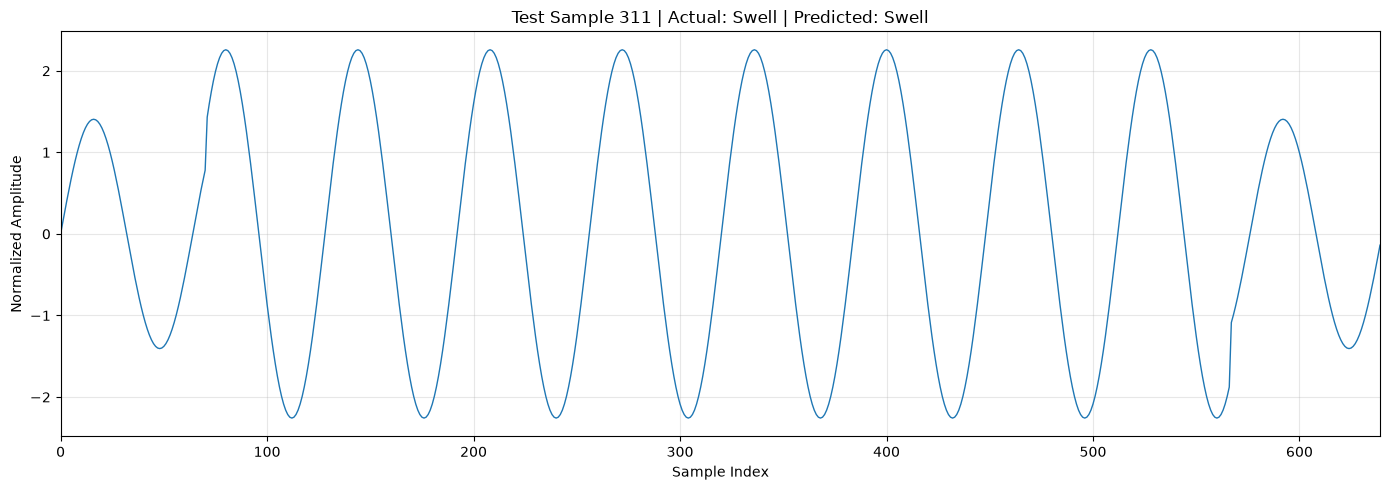

In [11]:
# ============================================================
# TEST SAMPLE PREDICTION
# USER ENTERS SAMPLE NUMBER: 1 - 320
# ============================================================

import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt


# ============================================================
# 1. LOAD TEST DATA
# ============================================================

TEST_CSV = "../dataset/PQD-16c-Data/test.csv"

test_df = pd.read_csv(TEST_CSV)

print("=" * 60)
print("TEST SAMPLE PREDICTION")
print("=" * 60)

print("Test dataset:", test_df.shape)


# ============================================================
# 2. CLASS NAMES
# ============================================================

class_names = [
    "Flicker",
    "Flicker+Harmonics",
    "Flicker+Sag",
    "Flicker+Swell",
    "Harmonics",
    "Impulsive Transient",
    "Interruption",
    "Interruption+Harmonics",
    "Normal",
    "Notch",
    "Oscillatory transient",
    "Sag",
    "Sag+Harmonics",
    "Spike",
    "Swell",
    "Swell+Harmonics"
]


# ============================================================
# 3. EXTRACT DATA
# ============================================================

test_labels = test_df.iloc[:, 0].values

test_signals = test_df.iloc[:, 1:].values.astype(
    np.float32
)


# ============================================================
# 4. TRAINING NORMALIZATION
# ============================================================

TRAIN_MEAN = 0.00017230
TRAIN_STD = 0.71135187

test_signals_normalized = (
    test_signals - TRAIN_MEAN
) / TRAIN_STD


# ============================================================
# 5. ASK USER FOR SAMPLE
# ============================================================

while True:

    try:

        sample_number = int(
            input(
                "\nEnter test sample number (1-320): "
            )
        )

        if 1 <= sample_number <= len(test_df):

            break

        print(
            f"Please enter a number between 1 and {len(test_df)}."
        )

    except ValueError:

        print(
            "Invalid input. Please enter an integer."
        )


# Convert human-readable sample number
# to Python array index

sample_index = sample_number - 1


# ============================================================
# 6. GET SAMPLE
# ============================================================

signal = test_signals_normalized[
    sample_index
]

actual_label = test_labels[
    sample_index
]


# ============================================================
# 7. CONVERT TO TENSOR
# ============================================================
#
# [640]
#   ↓
# [1, 640]
#   ↓
# [1, 1, 640]
#
# Final shape required by CNN:
# [batch, channel, signal_length]
# ============================================================

x = torch.tensor(
    signal,
    dtype=torch.float32
)

x = x.unsqueeze(0)
x = x.unsqueeze(0)

x = x.to(device)


# ============================================================
# 8. PREDICTION
# ============================================================

model.eval()

with torch.no_grad():

    logits = model(x)

    probabilities = torch.softmax(
        logits,
        dim=1
    )

    predicted_index = logits.argmax(
        dim=1
    ).item()

    confidence = probabilities[
        0,
        predicted_index
    ].item() * 100


predicted_label = class_names[
    predicted_index
]


# ============================================================
# 9. PRINT RESULT
# ============================================================

print()
print("=" * 60)
print(f"TEST SAMPLE {sample_number}")
print("=" * 60)

print(
    f"Actual Label    : {actual_label}"
)

print(
    f"Predicted Label : {predicted_label}"
)

print(
    f"Confidence      : {confidence:.2f}%"
)

print()

if actual_label == predicted_label:

    print("Result          : CORRECT")

else:

    print("Result          : INCORRECT")


# ============================================================
# 10. TOP 3 PREDICTIONS
# ============================================================

top_k = 3

top_probs, top_indices = torch.topk(
    probabilities[0],
    top_k
)

print()
print("Top Predictions:")
print("-" * 45)

for rank in range(top_k):

    idx = top_indices[rank].item()

    prob = top_probs[rank].item() * 100

    print(
        f"{rank + 1}. "
        f"{class_names[idx]:25s} "
        f"{prob:6.2f}%"
    )


# ============================================================
# 11. PLOT ACTUAL TEST SIGNAL
# ============================================================

plt.figure(figsize=(14, 5))

plt.plot(
    signal,
    linewidth=1
)

plt.title(
    f"Test Sample {sample_number} | "
    f"Actual: {actual_label} | "
    f"Predicted: {predicted_label}"
)

plt.xlabel("Sample Index")

plt.ylabel("Normalized Amplitude")

plt.xlim(
    0,
    len(signal) - 1
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()